# 02 · Recuperação (busca nos trechos da base)

Fase 4 do plano: comparar formas de busca, escolher a configuração **só no split dev**, definir o
limiar de recusa τ e medir **uma única vez** no split test. Este notebook lê os resultados gerados
por `scripts/avaliar_recuperacao.py` (etapas `ablacao`, `limiar` e `final`) em
`avaliacao/retrieval/`.

- **recall@k:** fração das perguntas respondíveis com pelo menos um trecho gold entre os k primeiros.
- **Gabarito v1 x v2:** o v2 (oficial) acrescenta trechos equivalentes aprovados pelo Pedro
  (`avaliacao/gold_equivalentes.yaml`); o v1 é mostrado para transparência.
- **τ:** nota mínima (cosseno do melhor trecho) para o sistema aceitar responder.

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import pandas as pd

from src.avaliacao.recuperacao import wilson

R = RAIZ / "avaliacao" / "retrieval"
ablacao = pd.read_csv(R / "ablacao_dev.csv")
limiar = json.loads((R / "limiar.json").read_text(encoding="utf-8"))
notas = pd.read_csv(R / "limiar_notas.csv")
curva = pd.read_csv(R / "limiar_curva.csv")
final = json.loads((R / "resultados_test.json").read_text(encoding="utf-8"))
print("configuração final:", final["configuracao"])

configuração final: {'modo': 'denso', 'reranker': None, 'top_k_final': 3, 'tau': 0.6038}


## 1. Ablação no dev (16 perguntas respondíveis)

In [2]:
cols = ["variante", "recall@1", "recall@3", "recall@5", "mrr", "ic95@3",
        "recall@1_v1", "recall@3_v1", "latencia_p50_s"]
ablacao[cols]

,variante,recall@1,recall@3,recall@5,mrr,ic95@3,recall@1_v1,recall@3_v1,latencia_p50_s
0,denso,0.750,0.938,0.938,0.833,[0.72; 0.99],0.375,0.562,0.000
1,bm25,0.438,0.562,0.688,0.528,[0.33; 0.77],0.312,0.375,0.005
2,hibrido,0.438,0.625,0.938,0.603,[0.39; 0.82],0.312,0.375,0.006
3,denso+reranker,0.688,0.875,0.875,0.781,[0.64; 0.97],0.375,0.562,0.263
4,bm25+reranker,0.562,0.875,0.875,0.708,[0.64; 0.97],0.375,0.688,0.248
5,hibrido+reranker,0.750,0.938,1.000,0.856,[0.72; 0.99],0.438,0.688,0.266


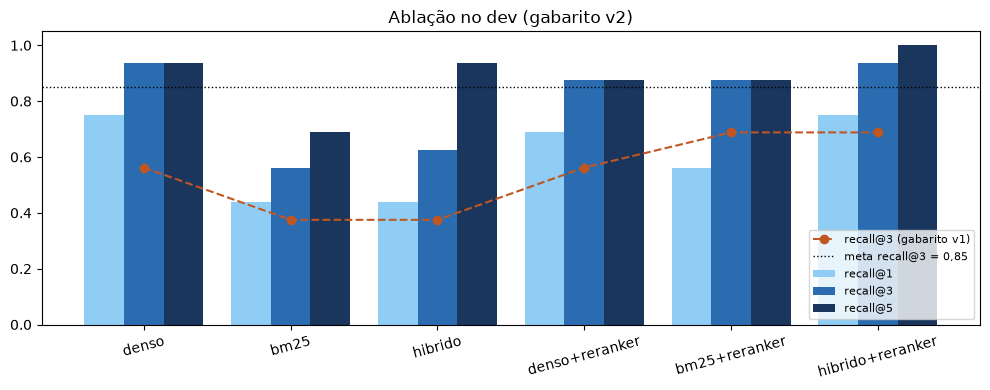

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
x = range(len(ablacao))
for i, (col, cor) in enumerate([("recall@1", "#90cdf4"), ("recall@3", "#2b6cb0"),
                                ("recall@5", "#1a365d")]):
    ax.bar([j + i * 0.27 for j in x], ablacao[col], width=0.27, label=col, color=cor)
ax.plot([j + 0.27 for j in x], ablacao["recall@3_v1"], "o--", color="#c05621",
        label="recall@3 (gabarito v1)")
ax.axhline(0.85, color="k", ls=":", lw=1, label="meta recall@3 = 0,85")
ax.set_xticks([j + 0.27 for j in x])
ax.set_xticklabels(ablacao["variante"], rotation=15)
ax.set_ylim(0, 1.05)
ax.set_title("Ablação no dev (gabarito v2)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**Escolha (critério declarado antes: recall@3, depois recall@1, depois latência):** a busca
densa empatou com a híbrida + reranker em recall@3 e recall@1 e é cerca de 100 vezes mais
rápida, sem disputar VRAM com o LLM. A híbrida + reranker teve MRR e recall@5 um pouco maiores
(uma pergunta de diferença) e fica registrada como alternativa. A diferença entre v1 e v2 mostra
quanto o gabarito original subestimava a busca.

## 2. Limiar de recusa τ (dev + conjunto de calibração)

In [4]:
print(json.dumps({k: limiar[k] for k in ("nota", "criterio", "tau", "tpr", "fpr",
                                           "n_positivas", "n_negativas")},
                 ensure_ascii=False, indent=1))
pd.DataFrame(limiar["por_subtipo"]).T

{
 "nota": "cosseno denso (top-1)",
 "criterio": "maior TPR das respondíveis com no máximo 5% das perguntas fora do domínio passando (opção B, Pedro, 08/11/2026); 'não consta' recusadas pelo LLM",
 "tau": 0.6038,
 "tpr": 0.903,
 "fpr": 0.043,
 "n_positivas": 31,
 "n_negativas": 23
}


,n,aceitas
coloquial,5,4
direta,7,7
fora_dominio,23,1
multi_trecho,2,2
nao_consta,12,3
respondivel,15,15
ruido,2,0


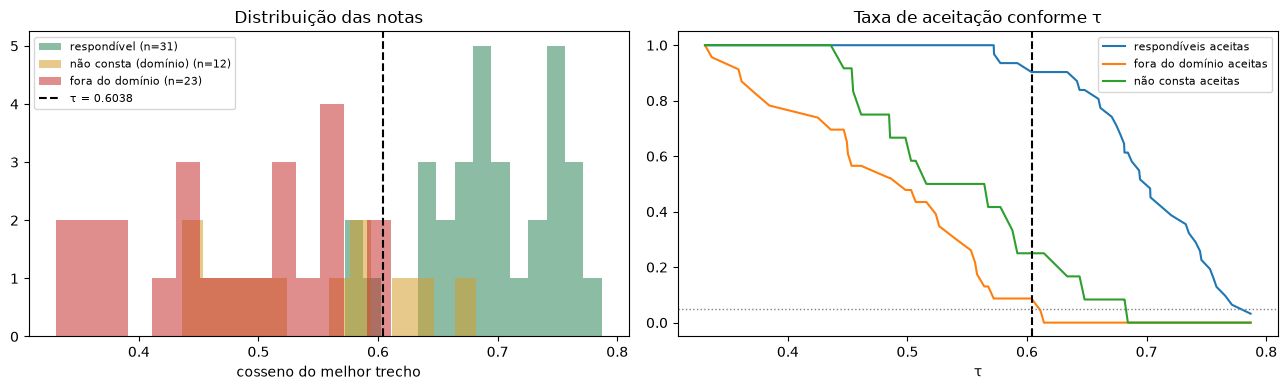

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
grupos = {"respondível": notas[notas.rotulo == "responder"].nota,
          "não consta (domínio)": notas[notas.subtipo == "nao_consta"].nota,
          "fora do domínio": notas[notas.subtipo == "fora_dominio"].nota}
for (nome, serie), cor in zip(grupos.items(), ["#2f855a", "#d69e2e", "#c53030"]):
    eixos[0].hist(serie, bins=14, alpha=0.55, label=f"{nome} (n={len(serie)})", color=cor)
eixos[0].axvline(limiar["tau"], color="k", ls="--", label=f"τ = {limiar['tau']}")
eixos[0].set_xlabel("cosseno do melhor trecho")
eixos[0].set_title("Distribuição das notas")
eixos[0].legend(fontsize=8)
eixos[1].plot(curva.tau, curva.tpr, label="respondíveis aceitas")
eixos[1].plot(curva.tau, curva.fpr, label="fora do domínio aceitas")
eixos[1].plot(curva.tau, curva.nao_consta_aceitas, label="não consta aceitas")
eixos[1].axvline(limiar["tau"], color="k", ls="--")
eixos[1].axhline(0.05, color="gray", ls=":", lw=1)
eixos[1].set_xlabel("τ")
eixos[1].set_title("Taxa de aceitação conforme τ")
eixos[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Leitura:** as perguntas fora do domínio ficam bem separadas das respondíveis, e o portão
as barra. As "não consta" do domínio falam de energia e têm notas parecidas com as respondíveis:
o portão não consegue separá-las sem recusar perguntas legítimas, sobretudo as coloquiais e as de
voz. Por decisão do Pedro (opção B), o τ foi calibrado contra o fora do domínio, e a recusa das
"não consta" fica com o LLM (gatilho b da política de recusa), a ser medida na Fase 5.

## 3. Medição única no test (36 perguntas; 26 respondíveis)

In [6]:
linhas = []
for split in ("dev", "test"):
    for gab, chave in (("v2", "recuperacao"), ("v1", "recuperacao_v1")):
        r = final[split][chave]["total"]
        for k in (1, 3):
            lo, hi = wilson(r[f"acertos@{k}"], r["n"])
            linhas.append({"split": split, "gabarito": gab, "métrica": f"recall@{k}",
                           "acertos": f"{r[f'acertos@{k}']}/{r['n']}",
                           "valor": round(r[f"recall@{k}"], 3), "IC95": f"[{lo:.2f}; {hi:.2f}]"})
pd.DataFrame(linhas)

,split,gabarito,métrica,acertos,valor,IC95
0,dev,v2,recall@1,12/16,0.750,[0.51; 0.90]
1,dev,v2,recall@3,15/16,0.938,[0.72; 0.99]
2,dev,v1,recall@1,6/16,0.375,[0.18; 0.61]
3,dev,v1,recall@3,9/16,0.562,[0.33; 0.77]
4,test,v2,recall@1,11/26,0.423,[0.26; 0.61]
5,test,v2,recall@3,17/26,0.654,[0.46; 0.81]
6,test,v1,recall@1,9/26,0.346,[0.19; 0.54]
7,test,v1,recall@3,14/26,0.538,[0.35; 0.71]


In [7]:
por_tipo = {s: {t: f"{v['acertos@3']}/{v['n']}" for t, v in final[s]["recuperacao"].items()}
            for s in ("dev", "test")}
pd.DataFrame(por_tipo).rename_axis("recall@3 por tipo (v2)")

,dev,test
recall@3 por tipo (v2),,
direta,7/7,9/11
total,15/16,17/26
coloquial,5/5,4/7
ruido,1/2,1/4
multi_trecho,2/2,3/4


In [8]:
portao = pd.DataFrame(final["test"]["portao"])
portao.groupby("tipo")["aceita"].agg(["sum", "count"]).rename(
    columns={"sum": "aceitas pelo portão", "count": "total"})

,aceitas pelo portão,total
tipo,,
coloquial,6,7
direta,11,11
fora_dominio,1,3
multi_trecho,3,4
nao_consta,1,4
ruido,1,4


## 4. Interpretação

- **Dev x test:** o recall@3 caiu de 0,938 (15/16) no dev para 0,654 (17/26) no test. Com amostras
  tão pequenas, os intervalos de confiança se sobrepõem. A análise pós-hoc das 9 falhas
  (`avaliacao/retrieval/analise_falhas_test.md`) mostra que cerca de 3 ou 4 delas trouxeram
  trechos que também respondem à pergunta, mas não estavam no gabarito.
- **Ponto fraco real: voz.** As perguntas com ruído de transcrição são as piores, tanto na busca
  quanto no portão. Essa é a primeira candidata a correção na Fase 8 (normalizar a pergunta de voz).
- **Tabelas:** a pergunta das 30 horas (T-037) não recuperou a tabela de limites. Trechos de tabela
  têm pouco texto parecido com a pergunta.
- **Número oficial do item 03:** recall@1 e recall@3 no test com o gabarito v2, configuração e τ
  definidos só no dev.